In [63]:
%pip install numpy pandas scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


In [64]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("EcoCore AI environment ready")

EcoCore AI environment ready


In [65]:
def generate_training_data(n=10000, seed=42):
    rng = np.random.default_rng(seed)

    cpu = rng.uniform(5, 100, n)
    memory = rng.uniform(10, 100, n)
    load = np.clip(cpu / 100 * rng.normal(0.9, 0.35, n), 0, 3)

    cpu_trend = rng.normal(1, 4, n)
    memory_trend = rng.normal(0.3, 1.5, n)

    # Simulated resource values at a future horizon
    future_cpu = np.clip(
        cpu + 3 * cpu_trend + rng.normal(0, 5, n), 0, 100
    )
    future_memory = np.clip(
        memory + 3 * memory_trend + rng.normal(0, 3, n), 0, 100
    )
    future_load = np.clip(
        load + np.maximum(cpu_trend, 0) * 0.01, 0, 3
    )

    # Target: future simulated pressure, not real outages
    risk = (
        (future_cpu >= 80) |
        (future_memory >= 85) |
        (future_load >= 1.2)
    ).astype(int)

    X = pd.DataFrame({
        "cpu_pct": cpu,
        "memory_pct": memory,
        "load_per_core": load,
        "cpu_trend": cpu_trend,
        "memory_trend": memory_trend,
    })

    return X, risk


X, y = generate_training_data()

print("Training samples:", len(X))
print("Simulated pressure rate:", round(y.mean() * 100, 2), "%")
display(X.head())

Training samples: 10000
Simulated pressure rate: 38.12 %


,cpu_pct,memory_pct,load_per_core,cpu_trend,memory_trend
0,78.525825,74.865555,0.204936,2.200000,-2.070158
1,46.693452,74.011399,0.355738,-4.471183,-1.778723
2,86.566802,28.242553,0.249364,-1.524002,1.138926
3,71.249963,13.298986,1.150358,5.073454,0.191423
4,13.946848,37.341957,0.135894,4.994759,-1.070984


In [66]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

model = RandomForestClassifier(
    n_estimators=120,
    max_depth=12,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("EcoCore model training complete.")

EcoCore model training complete.


In [67]:
predictions = model.predict(X_test)

metrics = {
    "Accuracy": accuracy_score(y_test, predictions),
    "Precision": precision_score(y_test, predictions, zero_division=0),
    "Recall": recall_score(y_test, predictions, zero_division=0),
    "F1 score": f1_score(y_test, predictions, zero_division=0),
}

display(
    pd.DataFrame(
        metrics.items(),
        columns=["Metric", "Score"]
    ).round(3)
)

print(classification_report(y_test, predictions, zero_division=0))
print("Confusion matrix:")
print(confusion_matrix(y_test, predictions))

,Metric,Score
0,Accuracy,0.942
1,Precision,0.901
2,Recall,0.952
3,F1 score,0.926


              precision    recall  f1-score   support

           0       0.97      0.94      0.95      1547
           1       0.90      0.95      0.93       953

    accuracy                           0.94      2500
   macro avg       0.93      0.94      0.94      2500
weighted avg       0.94      0.94      0.94      2500

Confusion matrix:
[[1447  100]
 [  46  907]]


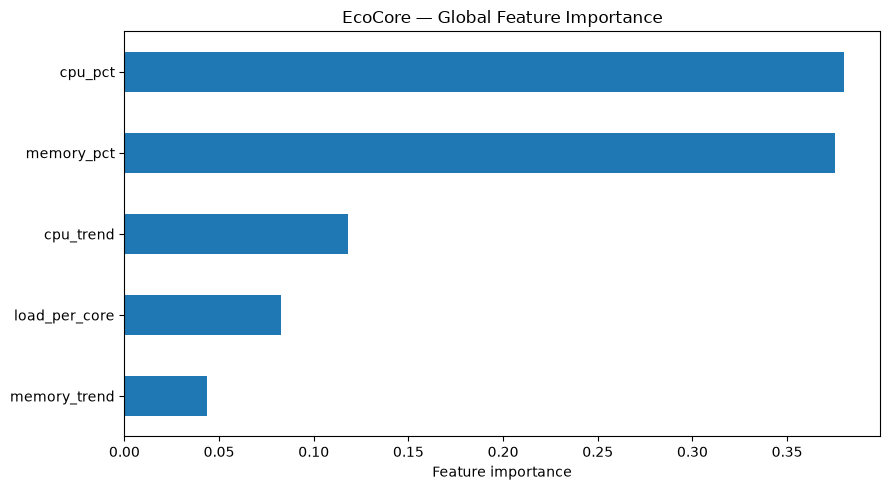

In [68]:
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values()

importance.plot.barh(
    figsize=(9, 5),
    title="EcoCore — Global Feature Importance"
)

plt.xlabel("Feature importance")
plt.tight_layout()
plt.show()

In [69]:
FEATURES = [
    "cpu_pct",
    "memory_pct",
    "load_per_core",
    "cpu_trend",
    "memory_trend",
]


def predict(metrics):
    """
    Input: telemetry dictionary.
    Output: model-estimated pressure risk and global feature importance.
    """
    row = pd.DataFrame(
        [{feature: float(metrics[feature]) for feature in FEATURES}],
        columns=FEATURES
    )

    probability = float(model.predict_proba(row)[0, 1])

    level = (
        "HIGH" if probability >= 0.70
        else "ELEVATED" if probability >= 0.40
        else "LOW"
    )

    explanation = (
        importance.sort_values(ascending=False)
        .head(3)
        .index.tolist()
    )

    return {
        "risk_probability": probability,
        "risk_level": level,
        "important_signals": explanation,
    }


example = {
    "cpu_pct": 82,
    "memory_pct": 76,
    "load_per_core": 1.1,
    "cpu_trend": 4.0,
    "memory_trend": 1.5,
}

result = predict(example)
print(result)

{'risk_probability': 0.9523000266650914, 'risk_level': 'HIGH', 'important_signals': ['cpu_pct', 'memory_pct', 'cpu_trend']}


In [70]:
metrics = {
    "cpu_pct": 82.0,
    "memory_pct": 76.0,
    "load_per_core": 1.1,
    "cpu_trend": 4.0,
    "memory_trend": 1.5
}

In [71]:
{
    "risk_probability": 0.75,
    "risk_level": "HIGH",
    "important_signals": [
        "cpu_pct",
        "memory_pct",
        "cpu_trend"
    ]
}

{'risk_probability': 0.75,
 'risk_level': 'HIGH',
 'important_signals': ['cpu_pct', 'memory_pct', 'cpu_trend']}

In [72]:
from telemetry import collect_metrics

metrics = collect_metrics()

In [73]:
import importlib
import telemetry

importlib.reload(telemetry)

metrics = telemetry.collect_metrics()

print(metrics)

{'timestamp': '2026-10-17T16:41:00.396908', 'cpu_pct': 0.0, 'memory_pct': 67.9, 'load_per_core': 0.034, 'process_count': 17, 'logical_cores': 3, 'cpu_trend': 0.0, 'memory_trend': 0.0}


In [74]:
result = predict(metrics)

print(result)

{'risk_probability': 0.0002628572433699543, 'risk_level': 'LOW', 'important_signals': ['cpu_pct', 'memory_pct', 'cpu_trend']}


In [75]:
import joblib

joblib.dump(model, "ecocore_model.joblib")
print("Model exported successfully")

Model exported successfully


In [76]:
from predictor import predict

test_metrics = {
    "cpu_pct": 95.0,
    "memory_pct": 88.0,
    "load_per_core": 1.60,
    "process_count": 180,
    "logical_cores": 3,
    "cpu_trend": 6.0,
    "memory_trend": 3.0
}

result = predict(test_metrics)

print(result)

{'risk_probability': 1.0, 'risk_level': 'HIGH', 'important_signals': ['cpu_pct', 'memory_pct', 'load_per_core']}
